# 01. Modeling, identification and simulation

Original study laboratory. All generated data are synthetic.

A well-mixed, constant-volume tank obeys $V\dot c=q(u-c)$.
With $V=100$ L and $q=10$ L/min, $G(s)=1/(10s+1)$ and
$c_{k+1}=a c_k+(1-a)u_k$, where $a=\exp(-T_s/10)$.
Estimate an ARX model from a persistently exciting experiment, then assess
one-step prediction and recursive free-run on a fresh input sequence.
Noise on the autoregressive regressor can bias least squares; a small residual
does not prove physical parameter accuracy.

## Prepare the environment

Run the next cell once in Colab. Locally, install `requirements.txt` and open this notebook within the repository. The cell only downloads the public repository when running in Colab and no checkout is present.

In [1]:
from pathlib import Path
import sys, subprocess
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not Path("python/intelligent_control").exists():
    checkout = Path("/content/intelligent-process-control")
    if not checkout.exists():
        subprocess.run(["git", "clone", "https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation.git", str(checkout)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(checkout / "requirements.txt")], check=True)
    import os
    os.chdir(checkout)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "python/intelligent_control").is_dir())
sys.path.insert(0, str(ROOT / "python"))
print("Environment ready")

Environment ready


## Read the method visually

![Unit 01 conceptual diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/course/figures/learning/unit-01.png)

Read the tank boundary from left to right: the two inlet streams mix, the outlet carries the current concentration, and balanced total flow fixes the volume. The right-hand diagram separates training from an independent validation input. In the computed figure, compare the training excitation with the held-out one-step and recursive traces; the latter propagates its own errors.

The conceptual diagram is deliberately separate from the computed experiment below. [Editable SVG](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/figures/learning/unit-01.svg).

## Run the experiment

Read the model and controller definitions alongside the results. Every rerun writes the metrics, trace CSV files and figure from the current parameters. Unit 7 includes nested optimization and costs more than the other units.

In [2]:
from intelligent_control.experiments import run_unit
import json
result = run_unit(1, ROOT / "laboratories/01-modeling-identification/results")
print(json.dumps(result["summary"], indent=2))

{
  "arx_coefficients": [
    0.9503764749525814,
    0.04909108826686848,
    0.00026345367266585734
  ],
  "estimated_tau_min": 9.823745604932348,
  "estimated_gain": 0.989270476451615,
  "free_run": {
    "max_abs_error": 0.0022159779442598726,
    "mean_abs_error": 0.0007655862042690801,
    "sse": 0.0004990119075765116,
    "mse": 8.303026748361258e-07,
    "rmse": 0.0009112094571700437,
    "vaf_percent": 99.99226497484072,
    "r_squared": 0.9999180695410953
  },
  "one_step": {
    "max_abs_error": 0.00036850478087502303,
    "mean_abs_error": 8.173286063993734e-05,
    "sse": 6.725592380698718e-06,
    "mse": 1.1209320634497863e-08,
    "rmse": 0.00010587407914356499,
    "vaf_percent": 99.99989043552742,
    "r_squared": 0.9999988928042781
  },
  "analytic_max_error": 2.220446049250313e-16,
  "split": "Independent excitation trajectories, seeds 21 and 73; noise in training only",
  "elapsed_seconds": 0.017259899992495775
}


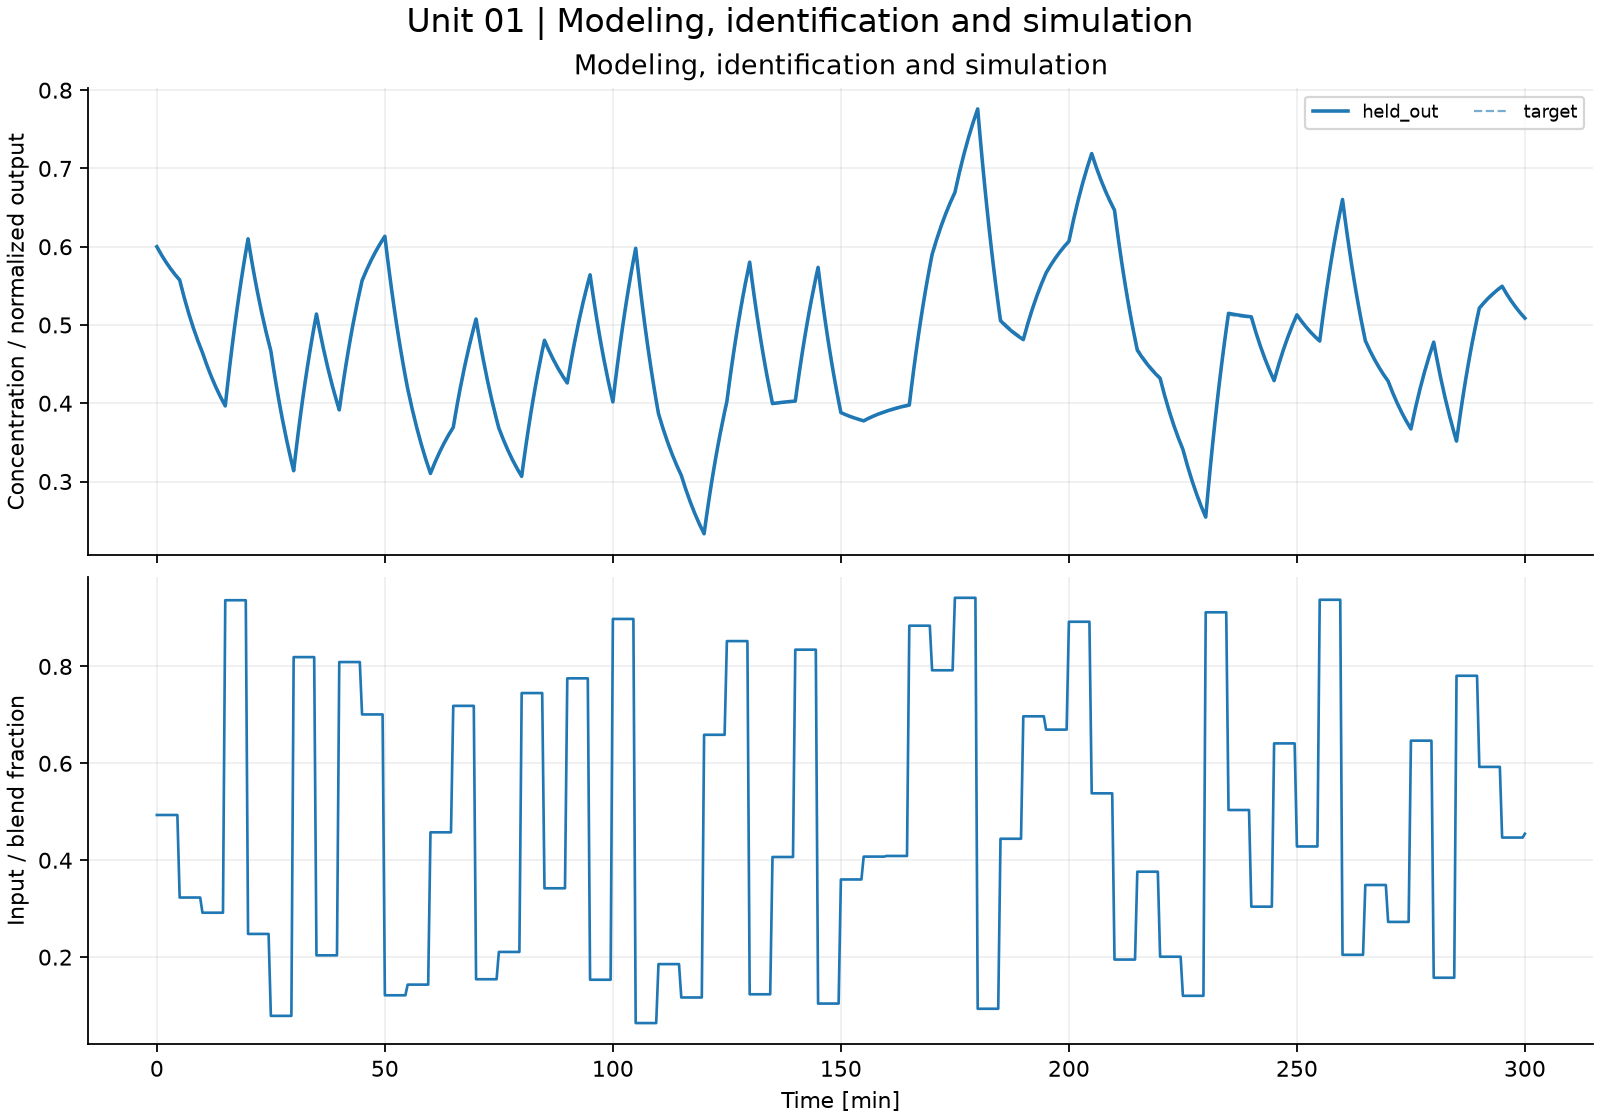

In [3]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "laboratories/01-modeling-identification/results/comparison.png")))

## Inspect the evidence

1. Identify the physical assumptions, input limits and units.
2. Explain a visible transient using the governing equation.
3. Change one model or controller parameter, rerun and compare the saved metrics.
4. State what the test does and does not establish.

Use the [course guide](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/course/README.md), [worked problems](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/problem-sets/README.md) and [benchmark inventory](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/README.md) for the corresponding derivations and extensions.

## Apply this unit to the article benchmarks

[Original article names and detailed TikZ atlas](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/DIAGRAMS.md) · [Download the vector atlas](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/figures/tikz/benchmark-atlas.pdf)

![Tennessee Eastman process control problem — article section 3.13](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/figures/tikz/13-tennessee-eastman.png)

The atlas identifies every benchmark by its original paper name and repository alias, with equipment, states and signals. The Tennessee Eastman companion plate maps the 12 commands and 41 measurements.

[Worked benchmark study for Unit 01](https://github.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/blob/main/benchmarks/learning/unit-01.md)

![Unit 01 benchmark study](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Intelligent-Systems-for-Process-Control-and-Automation/main/benchmarks/learning/figures/unit-01.png)

Read the per-model method, chosen signals, numerical results and interpretation in the linked study. The learning track declares its local-model approximations and separates equation-based experiments from external datasets and simulators. It does not turn an unavailable measured record into a synthetic benchmark result.